# ASTMNN — kết quả chi tiết (Wang et al. 2024)

`run_astmnn.py`: ba nhánh SaM (CNN + spatial attention trên patch w×w ô), TaM (3 BiLSTM + attention Luong trên t ngày) và GM (MLP trên biến của ô đích + vị trí/thời gian), gộp bằng trọng số học được λ = softmax(θ). w ∈ {5, 7, 9} và t ∈ {3, 4, 5} chọn bằng vòng lặp lồng trên ô validation của vòng trong (cùng ô với GTW-Tree). So sánh với các mô hình khác: `../../compare_models.ipynb`.

## 0. Thiết lập

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi'] = 110
MODEL_DIR = Path.cwd().parents[1]                        # pm25_map/model
sys.path.insert(0, str(MODEL_DIR))
import _data as D, _results as R
frame = D.build_frame(); cells = R.cell_table(frame)
OUT = MODEL_DIR / 'local_model' / 'ASTMNN' / 'output'
grid = pd.read_csv(OUT / 'inner_grid.csv') if (OUT / 'inner_grid.csv').exists() else pd.DataFrame()
preds = R.load_astmnn()
print('lưới:', f'{grid.fold.nunique()} fold, {len(grid)} tổ hợp' if len(grid) else 'chưa có',
      '· test:', sorted(preds['ASTMNN'].outer_fold.unique().tolist()) if preds else 'chưa có')

lưới: 5 fold, 45 tổ hợp · test: [0, 1, 2, 3, 4]


## 1. Vòng lặp lồng w × t

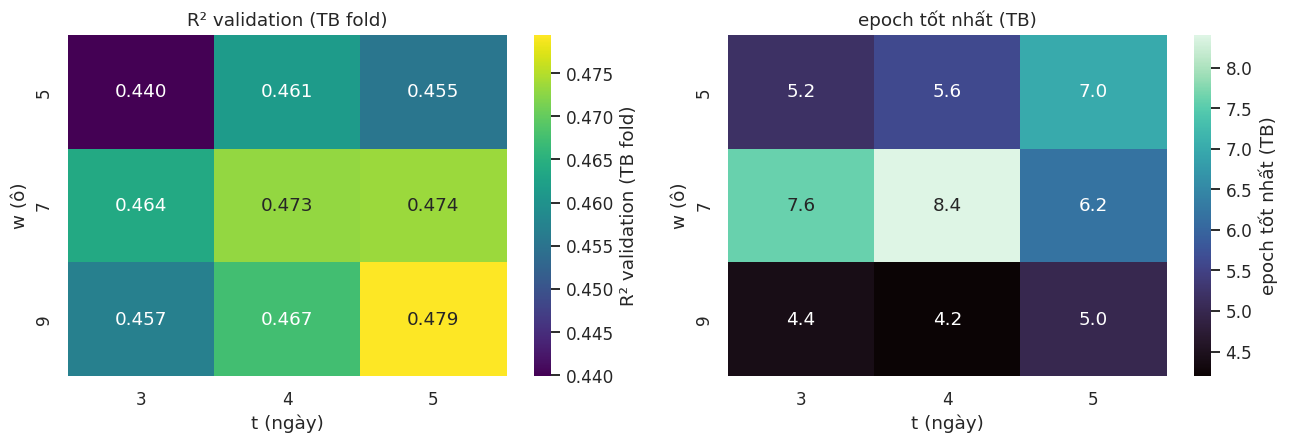

,w,t,R2,RMSE,best_epoch,epochs_run,lam_s,lam_t,lam_g
fold,,,,,,,,,
0,9,4,0.395,16.810,2,13,0.331,0.333,0.336
1,5,3,0.278,16.192,0,11,0.333,0.333,0.334
2,7,4,0.597,12.454,24,35,0.326,0.325,0.349
3,5,4,0.635,14.548,10,21,0.323,0.335,0.343
4,9,5,0.603,15.091,8,19,0.331,0.329,0.340


In [2]:
if len(grid):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, (val, lab, cm) in zip(axes, (('R2', 'R² validation (TB fold)', 'viridis'), ('best_epoch', 'epoch tốt nhất (TB)', 'mako'))):
        sns.heatmap(grid.pivot_table(index='w', columns='t', values=val, aggfunc='mean'), annot=True,
                    fmt='.3f' if val == 'R2' else '.1f', cmap=cm, ax=ax, cbar_kws={'label': lab})
        ax.set_title(lab); ax.set_ylabel('w (ô)'); ax.set_xlabel('t (ngày)')
    plt.tight_layout(); plt.show()
    display(grid.loc[grid.groupby('fold').R2.idxmax(), ['fold', 'w', 't', 'R2', 'RMSE', 'best_epoch', 'epochs_run', 'lam_s', 'lam_t', 'lam_g']].set_index('fold').round(3))

## 2. Đường học của mô hình được chọn ở mỗi fold

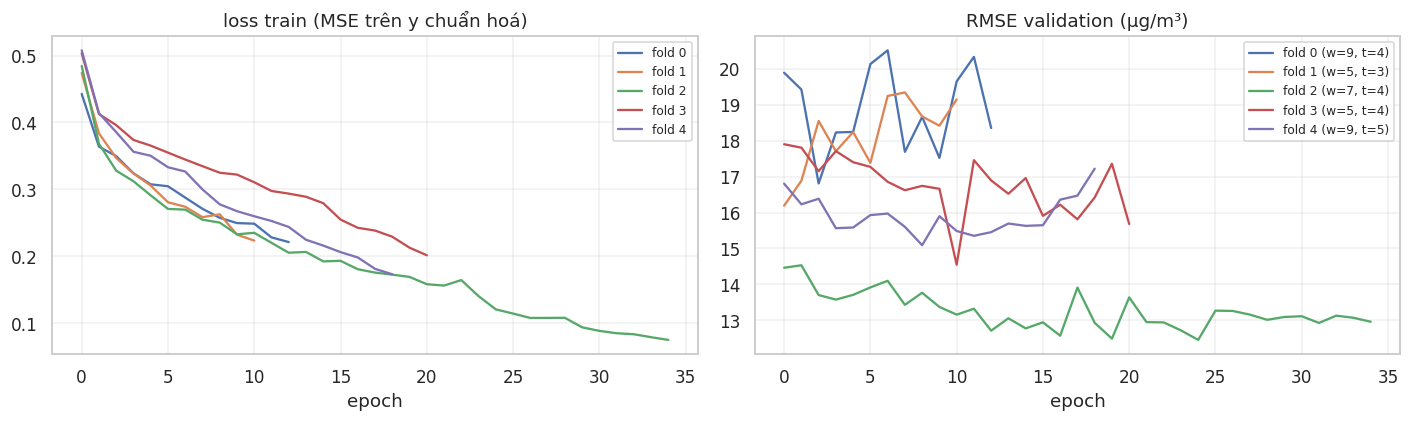

In [3]:
if len(grid):
    sel = grid.loc[grid.groupby('fold').R2.idxmax()]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for _, r in sel.iterrows():
        h = np.load(OUT / 'preds' / f'fold{int(r.fold)}_w{int(r.w)}_t{int(r.t)}.npz')['hist']
        axes[0].plot(h[:, 0], label=f'fold {int(r.fold)}'); axes[1].plot(h[:, 1], label=f'fold {int(r.fold)} (w={int(r.w)}, t={int(r.t)})')
    axes[0].set_title('loss train (MSE trên y chuẩn hoá)'); axes[1].set_title('RMSE validation (µg/m³)')
    for ax in axes: ax.set_xlabel('epoch'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 3. Trọng số ba nhánh λ (SaM, TaM, GM)
Paper gọi đây là trọng số thích nghi. Mỗi nhánh còn có lớp FC riêng có thể co giãn đầu ra, nên λ không xác định duy nhất. Nếu λ nằm gần 1/3 thì không thể đọc nó như mức đóng góp của từng nhánh.

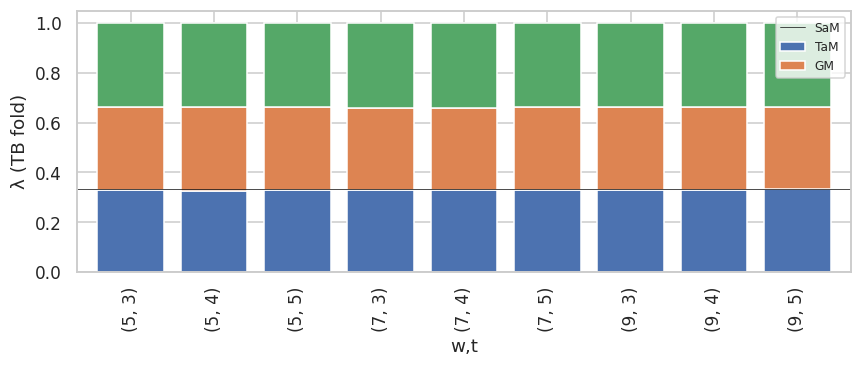

In [4]:
if len(grid):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    grid.groupby(['w', 't'])[['lam_s', 'lam_t', 'lam_g']].mean().plot.bar(ax=ax, stacked=True, width=0.8)
    ax.axhline(1 / 3, color='k', lw=0.5); ax.set_ylabel('λ (TB fold)'); ax.legend(['SaM', 'TaM', 'GM'], fontsize=8)
    plt.tight_layout(); plt.show()

## 4. Dự đoán test

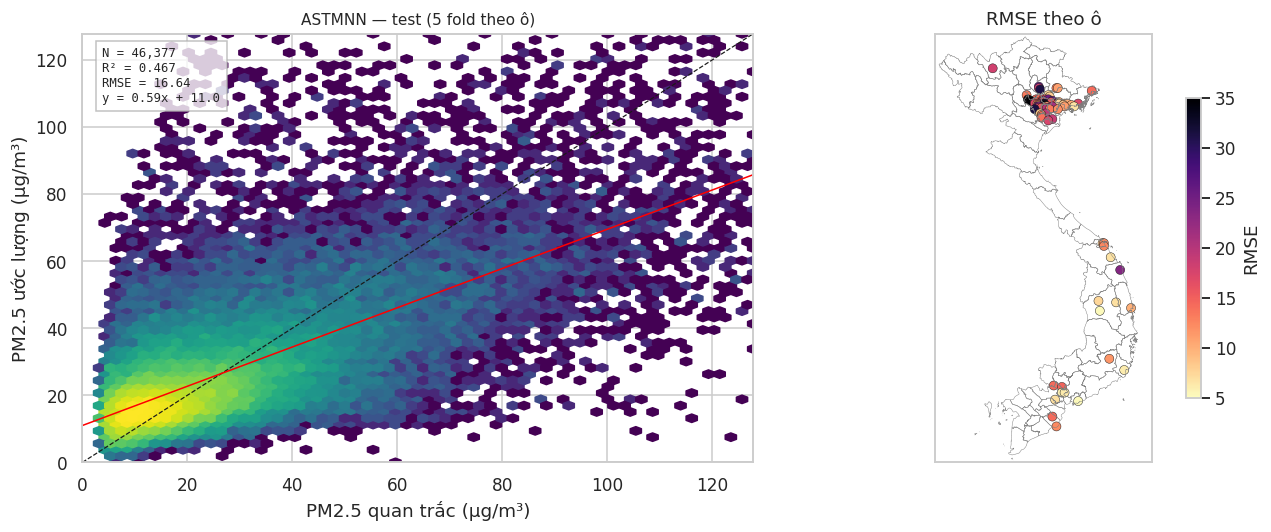

5 ô sai nhiều nhất:


,province,region,N,RMSE,bias
7590,Hà Nội,RRD,46.0,53.67,43.63
7428,Hà Nội,RRD,190.0,45.51,36.93
8080,Hưng Yên,RRD,212.0,39.63,-34.61
7920,Bắc Ninh,RRD,1827.0,33.05,17.23
8553,Hà Nội,RRD,212.0,31.45,-19.33


In [5]:
if preds:
    p = preds['ASTMNN']
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    R.density(axes[0], p[D.PM].values, p.pred.values, 'ASTMNN — test (5 fold theo ô)')
    J = R.joined(preds, frame); c = R.per_cell(J, 'ASTMNN', cells)
    R.vn_axes(axes[1]); sc = axes[1].scatter(c.lon, c.lat, c=c.RMSE.astype(float), cmap='magma_r', vmin=5, vmax=35, s=35, edgecolor='k', lw=0.3)
    plt.colorbar(sc, ax=axes[1], shrink=0.7, label='RMSE'); axes[1].set_title('RMSE theo ô')
    plt.tight_layout(); plt.show()
    worst = c.sort_values('RMSE', ascending=False).head(5)[['province', 'region', 'N', 'RMSE', 'bias']]
    print('5 ô sai nhiều nhất:'); display(worst.round(2))

## 5. Nhận xét (chạy 26/10/2026)

**Chỉ số gộp 5 fold theo ô**
- R² = 0,467 (R²_paper = 0,487), RMSE = 16,64 µg/m³, RPE = 64%.
- Độ dốc 0,59, tức là các giá trị cao bị kéo xuống.
- Theo fold: 0,494 / 0,534 / 0,375 / 0,463 / 0,470.
- Thấp hơn GTW-LightGBM (R² = 0,524, RMSE = 15,73) trên cùng 5 fold. So sánh với global ở `../../compare_models.ipynb`.

**Vòng lặp lồng w × t**
- R² validation trung bình qua các fold là 0,440–0,479, cao nhất ở w = 9, t = 5. Paper chọn w = 9, t = 3.
- Chênh lệch giữa các tổ hợp (~0,04) nhỏ hơn chênh lệch giữa các fold, nên mỗi fold chọn một tổ hợp khác nhau: (9,4), (5,3), (7,4), (5,4), (9,5).
- Ở dữ liệu này, kích thước patch và độ dài chuỗi gần như không quyết định kết quả.

**Mạng học thuộc dữ liệu nhanh và không ổn định**
- Epoch tốt nhất thường ở khoảng 0–10; riêng fold 1 tốt nhất ngay epoch đầu.
- RMSE validation nhảy ±2 µg/m³ giữa các epoch, trong khi loss train vẫn giảm đều.
- Nguyên nhân: mạng ~14 triệu tham số trên ~26 nghìn mẫu, học thuộc đặc điểm của ô train.
- Đáng thử: lr nhỏ hơn, tăng dropout / weight decay, thu nhỏ mạng, hoặc lấy trung bình nhiều seed. Các chỉnh này nằm ngoài cấu hình của paper.

**λ của ba nhánh ≈ 1/3**: không đọc được như mức đóng góp, vì lớp FC riêng của mỗi nhánh tự co giãn đầu ra. Muốn biết nhánh nào có ích thì phải bỏ thử từng nhánh (ablation).

**Ô sai nhiều nhất**
- Đều ở Hà Nội, Bắc Ninh, Hưng Yên; phần lớn có ít ngày (46–212), lệch hệ thống ±35–44 µg/m³.
- Đây giống đặc điểm riêng của trạm hoặc cảm biến hơn là lỗi mô hình: mô hình dựa vào ô lân cận không học được độ lệch riêng của một trạm.

**Chuẩn hoá đầu vào là bắt buộc**: nếu không lấy log1p và cắt z ở ±5, mạng ngoại suy ô núi Lào Cai lệch +83 µg/m³, và R² test của fold 0 thành −0,69.